---
title: "L7-10 · Open problems and critical synthesis"
short_title: "Open problems and critical synthesis"
subtitle: "A frontier is mapped by precise statements: what is proved, under which assumptions and against which baseline, what is only observed, and what test would close each open question."
description: "Audit a research claim down to its type signature and evidence, state open problems in quantum causal inference and quantum machine learning precisely with what is known and what would settle them, and turn one into a falsifiable research question."
tags: [level-7, coursebook]
---

(lesson-l7-10)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** A frontier is mapped by precise statements: what is proved, under which assumptions and against which baseline, what is only observed, and what test would close each open question.  
**Before this lesson.** [L6-06](#lesson-l6-06), [L6-07](#lesson-l6-07), [L6-09](#lesson-l6-09), [L7-04](#lesson-l7-04), [L7-05](#lesson-l7-05), [L7-09](#lesson-l7-09)  
**Lab.** [Variational circuits and gradients](../../labs/08-variational-gradients.ipynb)
:::

## What you will be able to do

- Write the type signature of a research claim (task, model class, access, accuracy, failure probability, method, resource bound, baseline, evidence type) and audit a claim against it, distinguishing existential evidence from universal theorems.
- Prove with a cut inflation that perfect three-way correlation is incompatible with the classical triangle network, and that for the noisy family the cut inflation is feasible exactly when $v \le 1/2$.
- For at least three open problems (latent quantum causal discovery, inflation hierarchies, indefinite causal order, trainability and simulability, dequantization, causal representations), state what is known with correct attribution, the open question, and a criterion that would settle it.

## Why this matters

Consider the sentence: "Our quantum causal learner tells cause from common cause with perfect accuracy: an exponential advantage." Each phrase sounds like a result. Yet one can build a correct computation, the two-qubit Pauli-correlation test of [L7-05](#lesson-l7-05), whose honest summary contains none of them: it applies to two restricted model classes, it identifies the structure for exactly half of one class (by volume) with exact data, it errs with finite shots, and it is not a speed-up at all but a difference in what the data identify. The distance between the sentence and the computation is where research judgment lives.

This closing lesson trains that judgment in both directions. Reading: every claim gets a type signature and an audit. Writing: every open problem is stated with what is known, with correct attribution, the precise question, and a test that would settle it, so that a proposal can be judged before it is pursued. One frontier technique, inflation, is worked through in full, so that the map of open problems rests on at least one piece of mathematics done by hand.

:::{dropdown} Key terms

**Claim type signature**
: The tuple (task, model class $\mathcal{M}$, access $\mathcal{O}$, accuracy $\varepsilon$, failure probability $\delta$, method $A$, resource bound $C$, baseline, evidence type) that a research claim must fix before it can be checked.

**Claim audit**
: Tracing a paper's strongest sentence back to its definitions and evidence, and rewriting it as the strongest statement the evidence supports.

**Separation**
: A pair of results: an upper bound on the cost of method $A$ on every instance of size $n$, and a lower bound on the cost of every competing method with the same access.

**Causal compatibility**
: A distribution is compatible with a causal structure if some choice of sources and local response functions (classical, or quantum when stated) reproduces it.

**Inflation**
: A larger causal structure built from copies of the original sources and parties; any compatible distribution must extend to a consistent distribution on suitable parts of the inflation [@inflation].

**Open problem**
: A precise question that the cited literature states or leaves unresolved, with a criterion for what would count as an answer.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_10 as _lessonfigs

## A claim has a type signature

:::{prf:definition} Research claim
:label: def-l7-10-claim
A **research claim** fixes: a task $T$ (what is to be estimated, decided or learned); a model class $\mathcal{M}$ (the processes, states or distributions allowed); the access $\mathcal{O}$ (which preparations, interventions, measurements, queries or data are available, at what cost); an accuracy $\varepsilon$ and failure probability $\delta$; a method $A$; a resource bound $C$ (shots, queries, gates, time, data, as a function of size $n$, $1/\varepsilon$ and $\log(1/\delta)$); a baseline; and the **evidence type**: theorem (proved under stated assumptions), numerical evidence (simulation with stated seeds and settings), or hardware evidence (data from a device, with its protocol).
:::

$$
\forall M \in \mathcal{M}:\quad P\big[\,\mathrm{err}\big(A^{\mathcal{O}}(M)\big) \le \varepsilon\,\big] \ge 1 - \delta \quad \text{with}\quad \mathrm{cost}\big(A^{\mathcal{O}}(M)\big) \le C\big(n, 1/\varepsilon, \log(1/\delta)\big)
$$ (eq-l7-10-claim)

Equation [](#eq-l7-10-claim) is the shape of a guarantee. An **advantage** claim adds a second statement about every competitor $B$ in a stated class with comparable access $\mathcal{O}'$: on some instances of size $n$ its cost is at least $C'(n)$. The two quantifiers matter. A simulation shows $\exists\, x:\ \mathrm{cost}_A(x) < \mathrm{cost}_B(x)$ for particular instances and a particular baseline. A separation needs $\forall x \in \mathcal{X}_n:\ \mathrm{cost}_A(x) \le \mathrm{poly}(n)$ and $\forall B\ \exists x \in \mathcal{X}_n:\ \mathrm{cost}_B(x) \ge 2^{\Omega(n)}$, and neither follows from the first. This is the resource accounting of [L7-06](#lesson-l7-06) and the protocol discipline of [L7-09](#lesson-l7-09) applied to reading.

:::{figure} ../../_static/animations/l7_10_claim_audit.mp4
:alt: A boxed hypothetical claim; four phrases are struck through and replaced by what the computation shows; then three quantified statements, the first crossed out as insufficient.
:width: 100%

Auditing a hypothetical claim: each phrase is replaced by what the lesson's computation actually shows, then the quantifiers a separation would need.
:::

:::{dropdown} What the animation shows
A box holds the hypothetical claim: our quantum causal learner tells cause from common cause with perfect accuracy, an exponential advantage. Four phrases are struck through in red and replaced in violet: quantum causal learner becomes a Pauli-correlation test on two qubits; cause versus common cause becomes only inside the two model classes of L7-05; perfect accuracy becomes exact data, identified for 1/2 of the class, and with 100 shots per basis, 0.044 wrong; exponential advantage becomes no speed-up, an identifiability gap. The second part writes three statements: there exists an instance $x$ with $\mathrm{cost}_A(x) < \mathrm{cost}_B(x)$ (a simulation: one instance, one baseline); for every instance of size $n$, $\mathrm{cost}_A(x) \le \mathrm{poly}(n)$ (an upper bound for A); for every classical $B$ there is an instance with $\mathrm{cost}_B(x) \ge 2^{\Omega(n)}$ (a lower bound against every classical B with the same access). The first statement is crossed out: it implies neither of the others.
:::

:::{prf:remark} Evidence types do not convert into each other
:label: rem-l7-10-evidence
No number of simulations proves a universal statement over a model class, and a theorem about a noiseless model does not show that a device realizes it. Hardware evidence about a device does not establish a scaling law. The audit records which type supports each part of a claim.
:::

## A worked audit

:::{prf:algorithm} Claim audit
:label: alg-l7-10-audit
1. Copy the strongest sentence of the abstract or conclusion.  
2. Fill in the type signature of [](#def-l7-10-claim) from the body; mark every slot that the paper leaves unstated.  
3. For each slot, find the evidence: theorem number, figure, table, or none.  
4. Check the baseline: is it the best known method with the same access, or a convenient one?  
5. Check the resource model: are data loading, state preparation, shots and classical post-processing counted?  
6. Read the limitations section and compare it with the abstract.  
7. Try a counterexample under relaxed assumptions (larger model class, noise, drift, finite shots).  
8. Rewrite the claim as the strongest sentence the evidence supports.
:::

Apply it to the hypothetical claim of the motivation, using the setting of [L7-05](#lesson-l7-05). Two qubits are measured in the same Pauli basis $\sigma_i \in \{X, Y, Z\}$. Common-cause models (a shared state) produce correlation triples $c = (c_1, c_2, c_3)$ filling the tetrahedron $T_{cc}$ with vertices $(-1,-1,-1), (-1,1,1), (1,-1,1), (1,1,-1)$ (the tetrahedron of Bell-diagonal states [@horodecki1996pra]); direct-cause models (a channel, in L7-05's convention) fill the dual tetrahedron $T_{dc} = -T_{cc}$ (the names of [L6-05](#lesson-l6-05)); the overlap is the octahedron $|c_1| + |c_2| + |c_3| \le 1$. The observation that such observational quantum correlations can separate the two structures, which classical observational data cannot, is due to Ried and coauthors [@ried2015].

:::{prf:proposition} Half of each tetrahedron is ambiguous
:label: prop-l7-10-half
The octahedron $O = \{c : |c_1| + |c_2| + |c_3| \le 1\}$ has volume $4/3$, each tetrahedron has volume $8/3$, and $O \subset T_{cc} \cap T_{dc}$. Hence for a correlation triple drawn uniformly from $T_{cc}$, the exact correlations determine the causal structure with probability exactly $1/2$.
:::

:::{prf:proof}
$O$ is the union of 8 congruent corner simplices $\{c : \pm c_i \ge 0,\ \sum_i |c_i| \le 1\}$ of volume $1/6$ each, total $4/3$. $T_{cc}$ is the cube $[-1,1]^3$ (volume 8) with four corner pyramids removed, each with three mutually perpendicular edges of length 2 and volume $\tfrac16 \cdot 2^3 = 4/3$; so its volume is $8 - 16/3 = 8/3$, and the same holds for $T_{dc}$. Every point of $O$ satisfies the four facet inequalities of $T_{cc}$, such as $1 - c_1 - c_2 - c_3 \ge 1 - \sum_i |c_i| \ge 0$, and likewise those of $T_{dc}$. Points of $T_{cc}$ outside $O$ are not in $T_{dc}$, because $T_{cc} \cap T_{dc} = O$ (the intersection of the two dual tetrahedra, [L7-05](#lesson-l7-05)). So the structure is determined exactly on $T_{cc} \setminus O$, of volume $8/3 - 4/3 = 4/3$, half of $T_{cc}$.
:::

The volume fraction, a Monte Carlo check with the stated uniform prior, and the finite-shot behavior of the test with $N$ shots per Pauli basis.


In [2]:
import numpy as np

# Correlation triples c = (<XX>, <YY>, <ZZ>) of two-qubit common causes fill the tetrahedron T_cc; those of
# direct causes fill T_ce = -T_cc (L7-05).  The overlap is the octahedron |c1| + |c2| + |c3| <= 1.
T_cc = np.array([[-1, -1, -1], [-1, 1, 1], [1, -1, 1], [1, 1, -1]], dtype=float)

def facets(c):                       # T_cc is where all four are >= 0
    x, y, z = c[..., 0], c[..., 1], c[..., 2]
    return np.stack([1 - x - y - z, 1 - x + y + z, 1 + x - y + z, 1 + x + y - z], axis=-1)

def classify(c):                     # +1 common cause, -1 direct cause, 0 undetermined
    octa = np.abs(c).sum(axis=-1) <= 1
    cc = (facets(c) >= -1e-12).all(axis=-1) & ~octa
    ce = (facets(-c) >= -1e-12).all(axis=-1) & ~octa
    return np.where(cc, 1, np.where(ce, -1, 0))

# Volumes: T_cc is the cube [-1, 1]^3 minus four corner pyramids of volume 4/3 each: 8 - 16/3 = 8/3.
# The octahedron has volume 4/3, so it holds exactly half of each tetrahedron.
print("octahedron / tetrahedron volume:", (4 / 3) / (8 / 3))

rng = np.random.default_rng(314)
c = rng.dirichlet(np.ones(4), size=4000) @ T_cc       # uniform common causes (a stated prior, not a fact)
lab = classify(c)
print(f"exact data: identified {np.mean(lab == 1):.3f}, wrong {np.mean(lab == -1):.3f}")
for n in (25, 100, 400, 1600):                        # n shots in each Pauli basis
    k = rng.binomial(n, (1 + c) / 2)                  # outcomes with ab = +1
    lab = classify(2 * k / n - 1)
    print(f"N = {n:4d}: identified {np.mean(lab == 1):.3f}, undetermined {np.mean(lab == 0):.3f}, "
          f"wrong {np.mean(lab == -1):.3f}")

octahedron / tetrahedron volume: 0.5
exact data: identified 0.502, wrong 0.000
N =   25: identified 0.339, undetermined 0.573, wrong 0.088
N =  100: identified 0.399, undetermined 0.557, wrong 0.044
N =  400: identified 0.443, undetermined 0.531, wrong 0.026
N = 1600: identified 0.472, undetermined 0.512, wrong 0.015


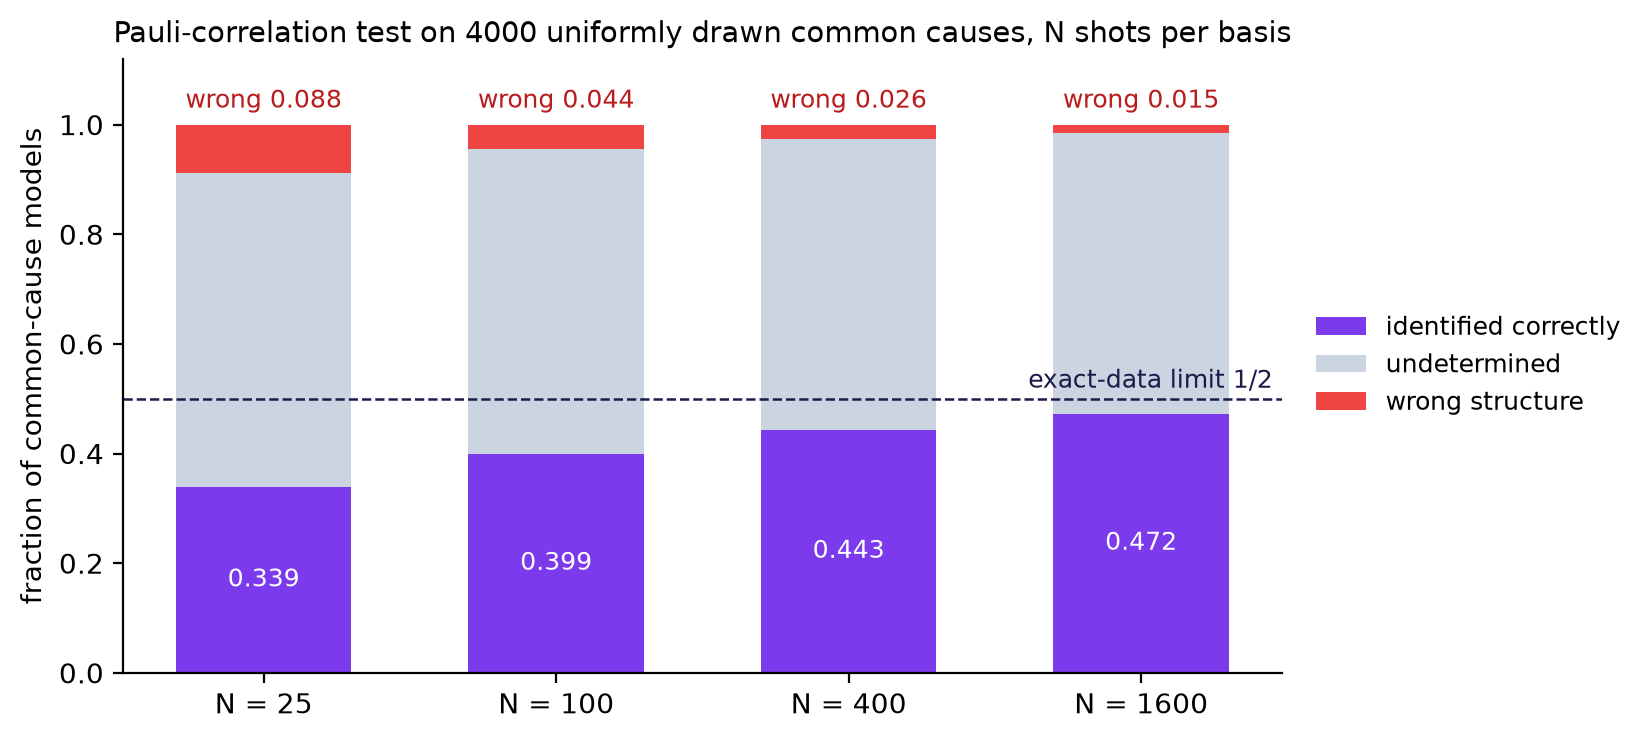

In [3]:
_show_mpl(_lessonfigs.audit_figure())

*The Pauli-correlation test applied to uniformly drawn common causes with $N$ shots per basis. With exact data half are identified and none are misclassified; with finite shots some estimates land on the wrong side of the octahedron.*

:::{prf:example} The audited sentence
:label: ex-l7-10-audited
From the code: with exact correlations 0.502 of 4000 uniformly drawn common causes are identified (the exact value is 1/2) and none are misclassified; with 100 shots per basis 0.399 are identified, 0.557 undetermined and 0.044 wrong. The strongest supported sentence is: *For two qubits, within the common-cause class of shared states and the direct-cause class of L7-05, exact Pauli correlations determine the causal structure outside the octahedron $|c_1| + |c_2| + |c_3| \le 1$, which is half of each class by volume; with $N$ shots per basis a simple plug-in rule errs on a fraction that decreases with $N$ (0.088 at $N = 25$, 0.015 at $N = 1600$, in simulation). This is a difference in identifiability, not a speed-up.* The volume statement is a theorem; the finite-shot rates are numerical evidence under a stated prior; nothing here is hardware evidence.
:::

## A frontier technique by hand: inflation

The triangle network has three observed parties $A, B, C$ and three independent latent sources: $\gamma$ feeds $A$ and $B$, $\alpha$ feeds $B$ and $C$, $\beta$ feeds $A$ and $C$. No party has a direct link to another. Deciding whether an observed $P(a, b, c)$ is compatible with this structure is hard because the latent variables can be arbitrary. The **inflation technique** of Wolfe, Spekkens and Fritz turns the question into constraints on a larger network built from copies of the sources [@inflation]; among other results they prove that the tripartite W-type distribution is incompatible with the triangle. Their first example uses the simplest such inflation, the cut inflation, to rule out perfect three-way correlation; it is worked out here in full, with the parties labeled so that the two copies of $\beta$ are the ones separated.

:::{prf:definition} Cut inflation of the triangle
:label: def-l7-10-cut
Take parties $A_2, B_1, C_1$, one copy $\gamma$ feeding $A_2$ and $B_1$, one copy $\alpha$ feeding $B_1$ and $C_1$, and two independent copies of the third source: $\beta_2$ feeding only $A_2$ and $\beta_1$ feeding only $C_1$. Each party uses the same response function as in the original network.
:::

:::{prf:lemma} Marginal constraints of the cut inflation
:label: lem-l7-10-cut
If $P$ is compatible with the triangle with classical sources, there is a distribution $Q(a_2, b_1, c_1)$ with $Q(A_2, B_1) = P(A, B)$, $Q(B_1, C_1) = P(B, C)$ and $Q(A_2, C_1) = P(A)\,P(C)$.
:::

:::{prf:proof}
Run the original model's response functions on the inflated network and let $Q$ be the resulting distribution. The pair $(A_2, B_1)$ depends on $(\beta_2, \gamma, \alpha)$ exactly as $(A, B)$ depends on $(\beta, \gamma, \alpha)$, with independent sources of the same distributions, so the joint law is the same; likewise for $(B_1, C_1)$. $A_2$ depends only on $(\beta_2, \gamma)$ and $C_1$ only on $(\alpha, \beta_1)$, which share no source, so $A_2$ and $C_1$ are independent with the marginals of $A$ and $C$.
:::

:::{prf:theorem} Perfect three-way correlation is incompatible with the triangle
:label: thm-l7-10-ghz
The distribution with $A = B = C$ and each a fair bit, $P(000) = P(111) = 1/2$, is incompatible with the triangle network with classical sources.
:::

:::{prf:proof}
Suppose it were compatible and take $Q$ from [](#lem-l7-10-cut). From $Q(A_2, B_1) = P(A, B)$, $A_2 = B_1$ with probability 1; from $Q(B_1, C_1) = P(B, C)$, $B_1 = C_1$ with probability 1. So $P(A_2 = C_1) = 1$. But $A_2$ and $C_1$ are independent fair bits, so $P(A_2 = C_1) = 1/2$, a contradiction.
:::

:::{figure} ../../_static/animations/l7_10_cut_inflation.mp4
:alt: A triangle of parties A, B, C with sources alpha, beta, gamma; beside it a chain A2, B1, C1 with two amber copies of beta; three marginal constraints; a contradiction; then bars comparing 1 - v with 1/2 as v sweeps from 0 to 1.
:width: 100%

The cut inflation: copy one source, keep the marginals that the copy cannot distinguish, and derive a contradiction. For the noisy family the test certifies incompatibility exactly when $v > 1/2$.
:::

:::{dropdown} What the animation shows
The triangle network shows parties $A$, $B$, $C$ and sources $\gamma$ (to $A$ and $B$), $\alpha$ (to $B$ and $C$) and $\beta$ (to $A$ and $C$), with the target distribution: $A = B = C$, each a fair bit. Beside it the cut inflation appears as a chain: $\beta_2$ to $A_2$, $\gamma$ to $A_2$ and $B_1$, $\alpha$ to $B_1$ and $C_1$, and $\beta_1$ to $C_1$, with the two copies of $\beta$ in amber. Three constraints are written: $Q(A_2, B_1) = P(A, B)$, $Q(B_1, C_1) = P(B, C)$, and $Q(A_2, C_1) = P(A)P(C)$. Then $A_2 = B_1$ and $B_1 = C_1$ give $P(A_2 = C_1) = 1$, while independence gives $P(A_2 = C_1) = 1/2$; the target is crossed out as incompatible with the triangle. In the second part the target becomes $P_v = v P_{\mathrm{GHZ}} + (1 - v) P_{\mathrm{unif}}$. The triangle inequality $P(A_2 \ne C_1) \le P(A_2 \ne B_1) + P(B_1 \ne C_1)$ becomes $\tfrac12 \le 1 - v$, so the inflation is feasible only if $v \le 1/2$. Two bars, $1 - v$ and $1/2$, change as $v$ sweeps from 0 to 1 and back to 0.60; once $1 - v$ falls below $1/2$ the label changes from this test is silent to incompatible: certified.
:::

:::{prf:proposition} The cut inflation for the noisy family
:label: prop-l7-10-noisy
Let $P_v = v\,P_{\mathrm{GHZ}} + (1 - v)\,P_{\mathrm{unif}}$ for $v \in [0, 1]$, where $P_{\mathrm{GHZ}}(000) = P_{\mathrm{GHZ}}(111) = 1/2$ and $P_{\mathrm{unif}}$ is uniform on $\{0,1\}^3$. The constraints of [](#lem-l7-10-cut) can be met if and only if $v \le 1/2$. Hence the cut inflation certifies that $P_v$ is incompatible with the classical triangle for every $v > 1/2$, and says nothing for $v \le 1/2$.
:::

:::{prf:proof}
Every pair of $P_v$ has uniform marginals and disagrees with probability $d = (1 - v)/2$. *Only if:* for any three binary variables, $\{A_2 \ne C_1\} \subseteq \{A_2 \ne B_1\} \cup \{B_1 \ne C_1\}$, so $P(A_2 \ne C_1) \le 2d = 1 - v$; independence of fair bits forces $P(A_2 \ne C_1) = 1/2$, so $v \le 1/2$. *If:* let $A_2, C_1$ be independent fair bits; set $B_1 = A_2$ when $A_2 = C_1$, and otherwise let a fair coin choose $B_1 = A_2$ or $B_1 = C_1$; finally flip $B_1$ with probability $r = 1/2 - v \in [0, 1/2]$. Then $P(A_2 \ne B_1) = \tfrac14(1 - r) + \tfrac34 r = \tfrac14 + \tfrac r2 = d$, and by the symmetry $A_2 \leftrightarrow C_1$ also $P(B_1 \ne C_1) = d$. The construction is invariant under flipping all three bits, so each pair has uniform marginals and equal off-diagonal entries, which pins each pairwise table to that of $P_v$.
:::


In [4]:
_show(_lessonfigs.inflation_explorer())

**Explore.** Move $v$. Left: the disagreement budget $P(A_2 \ne B_1) + P(B_1 \ne C_1) = 1 - v$ against the required $P(A_2 \ne C_1) = 1/2$. Right: the smallest entrywise violation of the cut-inflation constraints, from a linear program.

:::{dropdown} What the figure shows
The first panel shows two bars: $1 - v$ and the constant $1/2$. While $1 - v \ge 1/2$ the constraints can be met and the title says the test is silent; when $v > 1/2$ the budget is too small and the title reports incompatibility with the triangle. The second panel plots the optimal slack $t$ of a linear program that looks for $Q(A_2, B_1, C_1)$ matching the three pairwise tables within $t$ in every entry: $t = 0$ up to $v = 1/2$, then increasing linearly, for example 0.0167 at $v = 0.6$ and 0.0833 at $v = 1$, with a marker at the chosen $v$.
:::

The cut-inflation linear program, its slack for several $v$, and the feasibility threshold found by bisection.


In [5]:
import itertools
import numpy as np
from scipy.optimize import linprog

def noisy_ghz(v):                    # v * (000 or 111, each 1/2) + (1 - v) * uniform
    P = np.full((2, 2, 2), (1 - v) / 8)
    P[0, 0, 0] += v / 2
    P[1, 1, 1] += v / 2
    return P

def slack(v):
    """Smallest t such that some Q(A2, B1, C1) matches the cut-inflation marginals entrywise within t."""
    P = noisy_ghz(v)
    targets = {(0, 1): P.sum(axis=2), (1, 2): P.sum(axis=0), (0, 2): np.outer(P.sum(axis=(1, 2)), P.sum(axis=(0, 1)))}
    cells = list(itertools.product((0, 1), repeat=3))
    A_ub, b_ub = [], []
    for (i, j), T in targets.items():
        for a, b in itertools.product((0, 1), repeat=2):
            row = [1.0 if (k[i], k[j]) == (a, b) else 0.0 for k in cells]
            A_ub += [row + [-1.0], [-x for x in row] + [-1.0]]
            b_ub += [T[a, b], -T[a, b]]
    res = linprog([0.0] * 8 + [1.0], A_ub=A_ub, b_ub=b_ub, A_eq=[[1.0] * 8 + [0.0]], b_eq=[1.0],
                  bounds=[(0, None)] * 9, method="highs")
    return res.x[-1]

for v in (0.0, 0.5, 0.6, 1.0):
    print(f"v = {v:.1f}: LP slack {slack(v):.4f}")
lo, hi = 0.0, 1.0
for _ in range(30):                  # bisection for the feasibility threshold
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if slack(mid) <= 1e-9 else (lo, mid)
print("threshold v* =", round((lo + hi) / 2, 6))

v = 0.0: LP slack 0.0000
v = 0.5: LP slack 0.0000
v = 0.6: LP slack 0.0167
v = 1.0: LP slack 0.0833
threshold v* = 0.5


:::{important} Where the open problem is
Larger inflations give a hierarchy of tests. For classical latent variables, Navascues and Wolfe later proved that the inflation hierarchy converges: a distribution that passes the $n$-th level is within Euclidean distance $O(n^{-1/2})$ of a compatible one [@navascues2020]. For quantum sources, Wolfe and coauthors introduced quantum inflation as a technique to falsify quantum causal models, without a completeness claim [@wolfe2021]; Ligthart, Gachechiladze and Gross constructed a modified quantum inflation hierarchy that provably converges, for models in which local subsystems are commuting observable algebras, and note that no proof of completeness of the original quantum hierarchy had been given [@ligthart2023].
:::

## An atlas of open problems

Each entry below has three parts. **Known** cites what has been shown, with its assumptions. **Open** is a question the cited sources state or leave unresolved, as of writing. **Solved when** is this lesson's own criterion for an answer, offered so that a proposal can be judged; it is not a consensus of the field.

:::{figure} ../../_static/animations/l7_10_open_problem_atlas.mp4
:alt: Six cards in a grid; the camera zooms into each in turn as its Known, Open and Solved when lines appear, then zooms back out.
:width: 100%

Six open problems, each with what is known, the open question and a criterion for an answer.
:::

:::{dropdown} What the animation shows
Six cards are arranged in two rows: Latent quantum causal discovery; Inflation hierarchies; Certifying indefinite causal order; Trainable yet not simulable?; Dequantization and the power of data; Quantum causal representations. The camera zooms into each card in turn and three blocks appear. Latent quantum causal discovery: known, discovery from a full process matrix with a Markov test, and unravelling under bounded information loss; open, what is identifiable when some quantum systems are latent and access is limited; solved when, equivalence classes are characterized with a sound, complete, finite-sample algorithm. Inflation hierarchies: known, the classical hierarchy converges and a modified quantum one converges for commuting operators; open, whether the original quantum hierarchy is complete and which level is needed in practice; solved when, a convergence proof or counterexample with explicit level bounds. Certifying indefinite causal order: known, witnesses certify nonseparability of the switch assuming trusted devices; open, whether causal-inequality violations are physical and how to certify with weaker assumptions; solved when, a test that no causally ordered process passes, with every device assumption stated. Trainable yet not simulable: known, barren plateaus for random deep circuits and many plateau-free models are simulable; open, a model family provably trainable and not efficiently classically simulable; solved when, a proof of both for one family or a general simulation theorem. Dequantization and the power of data: known, classical learners with data can rival quantum models and some speedups are dequantized; open, natural tasks on classical data with an end-to-end provable advantage; solved when, a separation against all classical algorithms with equal access, data loading counted. Quantum causal representations: known, latent causal variables are identifiable only under assumptions such as interventions; open, whether quantum measurement structure helps identify them; solved when, an identifiability theorem that fails without the quantum structure. The camera zooms out and a note says these are open in the cited sources as of writing, and the solved-when tests are this lesson's criteria.
:::

**1. Latent quantum causal discovery.** *Known:* quantum causal models allow quantum common causes and quantum nodes [@costa; @allen; @barrett]. Giarmatzi and Costa give an algorithm whose input is a process matrix; it decides whether the process is Markovian (causally ordered, with all relevant common causes included) and, if so, outputs a causal model [@giarmatzi]. Bai and coauthors recover the causal structure of interactions inside a multipartite quantum process efficiently, under the assumption of bounded information loss and a threshold on causal dependence [@unravelling]. Liu and coauthors decide among five causal structures for a bipartite system at two times from light-touch coarse-grained measurements [@hypothesis]. In two-qubit model classes, observational Pauli correlations can separate cause from common cause [@ried2015]. Classically, with latent variables, constraint-based discovery returns an equivalence class rather than a graph [@spirtes]. *Open:* a characterization of what is identifiable (the analog of Markov equivalence classes) when some systems are latent and quantum and only a restricted set of instruments is available. *Solved when:* a theorem characterizing the equivalence classes for a stated access model, with an algorithm that returns exactly the class and finite-sample guarantees.

**2. Inflation hierarchies.** *Known:* inflation gives necessary conditions for compatibility [@inflation]; the classical hierarchy converges, and a modified quantum hierarchy converges in the commuting-operator setting (see the callout above). *Open:* completeness of the original quantum inflation hierarchy, and how high a level is needed for networks of practical size. *Solved when:* a convergence proof or a counterexample for the original hierarchy, ideally with explicit bounds on the level needed for a given accuracy.

**3. Certifying indefinite causal order.** *Known:* the process-matrix framework allows correlations with no definite causal order, including violations of causal inequalities in the formalism [@ocb]. Causal witnesses detect causal nonseparability; the quantum switch [@switch] is causally nonseparable but does not violate any causal inequality [@process]. Procopio and coauthors implemented a photonic quantum switch [@procopio], and Rubino and coauthors verified causal nonseparability with a causal witness, under assumptions about the devices [@rubino]. *Open:* whether processes that violate causal inequalities can be realized physically, and how to certify indefinite causal order with weaker assumptions on the devices. *Solved when:* a realization or a principle that rules such processes out; or a certification test, with every device assumption stated, that no causally ordered process can pass.

The quantum switch with control $|+\rangle$, computed with the course package: anticommuting $A, B$ send the control to $|-\rangle$ with certainty, commuting ones to $|+\rangle$. What these statistics say about causal order depends on assumptions about how the boxes were used, which is what problem 3 is about.


In [6]:
import numpy as np
from qcai import science as sci

# Quantum switch of two unitary channels A and B with control |+> (Kraus form of the switch paper):
# W = |0><0| (x) BA + |1><1| (x) AB.  Measure the control in the |+>, |-> basis.
minus = np.array([1, -1]) / np.sqrt(2)
P_minus = np.kron(np.outer(minus, minus), np.eye(2))
rho = sci.dm(sci.ket(0.7, 0.3))                       # any target state
for name, A, B in (("A = X, B = Z (anticommute)", sci.X, sci.Z), ("A = X, B = X (commute)", sci.X, sci.X)):
    out = sci.quantum_switch(rho, [A], [B])
    print(f"{name}: P(control = |->) = {np.real(np.trace(P_minus @ out)):.6f}")

A = X, B = Z (anticommute): P(control = |->) = 1.000000
A = X, B = X (commute): P(control = |->) = 0.000000


**4. Trainable yet not simulable?** *Known:* for parameterized circuits that are random enough (forming 2-designs), gradient variance vanishes exponentially in the number of qubits [@plateaus], and noise can also flatten the landscape [@noise]; see [L7-04](#lesson-l7-04). In a perspective article, Cerezo and coauthors collect evidence, case by case, that many models proven free of barren plateaus also admit efficient classical simulation, possibly after an initial phase of collecting data from the quantum device; they argue from examples and state caveats, and do not prove a general implication [@cerezo2025]. *Open:* is there a family of parameterized quantum models that is provably trainable (gradients not exponentially small) and provably not efficiently classically simulable, in a precise sense? *Solved when:* a proof of both properties for one family under standard complexity assumptions, or a general theorem that trainability in a stated sense implies efficient simulation.

**5. Dequantization and the power of data.** *Known:* Huang and coauthors show that classical learning algorithms given data can be competitive with quantum kernel models in some settings, with a prediction-error bound within a factor set by the geometric difference of the two kernels, and give a geometric test for when a quantum kernel could help [@advantage]; see [L7-03](#lesson-l7-03). Tang gave a classical algorithm for the recommendation task with sample access whose running time is only polynomially slower than the quantum algorithm it was compared with, removing the exponential speed-up claimed for that task [@tang2019]. *Open:* natural learning tasks on classical data with an end-to-end provable quantum advantage, counting data loading, state preparation and readout. *Solved when:* a separation against every classical algorithm with the same access to the data, with all costs in the ledger of [L7-06](#lesson-l7-06).

**6. Quantum causal representations.** *Known:* causal representation learning seeks high-level causal variables from low-level observations, and Scholkopf and coauthors argue that this requires assumptions such as interventions, multiple environments or sparse mechanism changes [@scholkopf]; identification in the sense of [L4-07](#lesson-l4-07) is a precondition [@bareinboim]. *Open:* this is a research direction more than a stated problem: whether the operational structure of quantum measurements (tomographic completeness, the choice of measurement basis as an intervention) can identify latent causal variables that classical observations cannot. *Solved when:* an identifiability theorem for a stated class of quantum data-generating processes that fails when the same data are restricted to a single classical measurement basis.

```{mermaid}
graph LR
  P1[Latent quantum discovery] --- L5[L7-05 identifiability]
  P2[Inflation hierarchies] --- L5
  P3[Indefinite causal order] --- L6[L6-07 process matrices]
  P4[Trainable vs simulable] --- L4[L7-04 barren plateaus]
  P5[Dequantization and data] --- L3[L7-03 kernels]
  P5 --- L6b[L7-06 resources]
  P6[Causal representations] --- L5
  P1 --- L7[L7-07 shadows]
  P1 --- L9[L7-09 protocols]
  P4 --- L9
```

*The six open problems and the lessons whose tools they use.*

## From open problem to research question

A research question is an open problem cut down to a size that one study can answer, with a comparison that can fail. The original direction is rarely the question: "is quantum causal discovery more efficient?" has no truth value until the model class, access, accuracy and baseline are fixed.

:::{prf:example} Adaptive designs for channel discrimination
:label: ex-l7-10-adaptive
Direction: adaptive experiment selection for quantum causal discovery. Question: for discriminating a direct cause from a common cause in the two-qubit classes of [L7-05](#lesson-l7-05), does choosing the next Pauli basis adaptively reduce the shots needed for error at most $\delta$, compared with the best fixed allocation at equal total shots? Assumptions: trusted measurement calibration; true triples at distance at least $\eta$ from the octahedron. Falsifier: equal or higher error at equal shots, or a gain that disappears under calibration drift, which would be reported as the boundary of the method. A general causal advantage is not claimed from this restricted result.
:::

:::{tip} A boundary is a contribution
Showing exactly where a method stops working (a noise level, a model class, a cost left out of an earlier comparison) is a result. Many of the known entries in the atlas above are of this kind: barren plateaus bound trainability, dequantization bounds speed-ups, and the fact that the switch violates no causal inequality [@process] marks what a causal-inequality test cannot detect.
:::

## Worked example

:::{admonition} Auditing a hypothetical claim to its supported form
:class: tip

Audit the hypothetical sentence "Our quantum causal learner tells cause from common cause with perfect accuracy: an exponential advantage", using the two-qubit Pauli-correlation test as the method actually run.

1. Type signature. Task: decide common cause versus direct cause. Model class: shared two-qubit states, and channels with a maximally mixed, measured and re-prepared input (L7-05). Access: projective $XX$, $YY$, $ZZ$ measurements, $N$ shots each. Method: classify by the position of the estimated triple relative to $T_{cc}$, $T_{dc}$ and the octahedron. Baseline: classical observational data, which do not identify the direction at all. Evidence: a theorem for exact data, simulation for finite $N$.
2. Accuracy with exact data: by [](#prop-l7-10-half), the structure is determined for exactly half of each class by volume (the Monte Carlo check gives 0.502 of 4000), and is undetermined, not wrong, for the other half. "Perfect accuracy" is false; "never wrong with exact data" is true.
3. Finite shots (numerical evidence, stated prior): identified 0.339, undetermined 0.573, wrong 0.088 at $N = 25$; identified 0.399, wrong 0.044 at $N = 100$; identified 0.472, wrong 0.015 at $N = 1600$.
4. Advantage: there is no cost comparison at all; the quantum data identify something classical observational data cannot. "Exponential advantage" has no referent, and the quantifier check of [](#eq-l7-10-claim) fails at the first step.

**Result.** Supported sentence: for two qubits in the stated model classes, exact Pauli correlations determine the causal structure outside the octahedron, half of each class by volume, and a plug-in rule with $N$ shots per basis errs on a fraction that decreases with $N$ in simulation; this is an identifiability difference, not a speed-up.
:::

## Exercises

**1. (Core)** A paper reports that its quantum model beats a classical neural network on three datasets. Fill in the type signature of [](#def-l7-10-claim) as far as this sentence allows, mark the missing slots, and say which evidence type it is.

:::{dropdown} Solution
Task: the three prediction tasks; model class: the three data distributions only; access: unstated (how the data are loaded into the circuit, how many shots); accuracy and failure probability: unstated or as reported test error without uncertainty; method: the quantum model; resource bound: unstated; baseline: one classical network, not the best classical method with equal access; evidence: numerical (or hardware) evidence of an existential kind, $\exists$ instances where $A$ beats one $B$. It establishes neither an upper bound over a class nor a lower bound against all classical methods.
:::

**2. (Core)** For the noisy family $P_v$, decide what the cut inflation says at $v = 0.6$ and at $v = 0.4$.

:::{dropdown} Solution
At $v = 0.6$: the disagreement budget is $1 - v = 0.4 < 1/2$, so by [](#prop-l7-10-noisy) no $Q$ meets the constraints and $P_{0.6}$ is incompatible with the classical triangle. At $v = 0.4$: $1 - v = 0.6 \ge 1/2$, the constraints can be met (with $r = 0.1$ in the construction), and the cut inflation is silent: it neither proves nor disproves compatibility.
:::

**3. (Stretch)** Verify the construction in the proof of [](#prop-l7-10-noisy) for $v = 0.3$: compute $r$ and $P(A_2 \ne B_1)$, and check that the pair $(A_2, B_1)$ has the table of $P_{0.3}$.

:::{dropdown} Solution
$r = 1/2 - 0.3 = 0.2$. Before the flip, $P(A_2 \ne B_1) = P(A_2 \ne C_1) \cdot \tfrac12 = \tfrac14$. After flipping with probability $r$: $\tfrac14(1 - 0.2) + \tfrac34(0.2) = 0.2 + 0.15 = 0.35 = (1 - 0.3)/2$. By the global flip symmetry, $P(01) = P(10) = 0.175$ and $P(00) = P(11) = 0.325$, which is the $(A, B)$ table of $P_{0.3}$: $P(a = b) = 0.3 + 0.7/2 = 0.65$, split equally.
:::

**4. (Stretch)** Rewrite the sentence "Quantum inflation solves quantum causal compatibility" so that it is accurate for the works described in this lesson.

:::{dropdown} Solution
For example: "Quantum inflation gives a hierarchy of tests that can falsify compatibility of correlations with a quantum causal network; a modified version of the hierarchy is known to converge when local subsystems are modeled as commuting observable algebras, while completeness of the original hierarchy is, to our knowledge, open." The classical statement (the classical hierarchy converges) should not be transferred to the quantum case.
:::

**5. (Challenge)** Prove that the octahedron $|c_1| + |c_2| + |c_3| \le 1$ equals $T_{cc} \cap T_{dc}$, using the facet inequalities $1 - s_1 c_1 - s_2 c_2 - s_3 c_3 \ge 0$, where $T_{cc}$ uses the sign patterns $(1,1,1)$, $(1,-1,-1)$, $(-1,1,-1)$ and $(-1,-1,1)$ for $s$, and $T_{dc}$ the negated patterns.

:::{dropdown} Solution
Together the two tetrahedra impose $1 - s\cdot c \ge 0$ for all eight sign vectors $s \in \{\pm1\}^3$ (the four patterns with product $+1$ and their negatives, product $-1$). Maximizing $s \cdot c$ over all eight sign vectors gives $\sum_i |c_i|$ (choose $s_i = \operatorname{sign} c_i$). So $c$ lies in both tetrahedra exactly when $\sum_i |c_i| \le 1$.
:::

**6. (Challenge)** Choose one open problem from the atlas and write a research question with: the model class, the access, one identifying assumption, the baseline, the evidence type you aim for, and one result that would count against your proposed method.

:::{dropdown} Solution
Sample answer (problem 1): For two-qubit processes that are probabilistic mixtures of one shared state and one channel from the classes of L7-05, with only Pauli measurements and $N$ shots per basis, can the mixing weight be identified and estimated? Assumption: the mixture components lie outside the octahedron and measurements are calibrated. Baseline: the plug-in classifier of this lesson applied to the pure components. Evidence: an identifiability theorem plus a finite-sample bound, checked by a simulation protocol written in advance (L7-09). Counter-result: two different (weight, component) pairs that produce the same correlation triple, which would show the weight is not identified. Any answer is acceptable that fixes every slot and names a falsifying observation.
:::

## Check your understanding

**1. Which statement belongs in a research conclusion?**

- **A.** A universal advantage inferred from one toy simulation
- **B.** A measured or proved result together with its model class and access limits
- **C.** An open question presented as an established theorem
- **D.** A speed-up stated without the baseline it was compared with

:::{dropdown} Show the answer
**B. A measured or proved result together with its model class and access limits**

A defensible conclusion matches the scope of the evidence: the model assumptions and access limits determine where the proved or measured result applies.
:::

**2. For the noisy family $P_v$, the cut-inflation constraints can be met at $v = 0.4$. What does this show?**

- **A.** That $P_{0.4}$ is incompatible with the triangle
- **B.** That quantum sources are needed for $P_{0.4}$
- **C.** That $P_{0.4}$ is compatible with the triangle
- **D.** Nothing about compatibility: the cut inflation is only a necessary condition

:::{dropdown} Show the answer
**D. Nothing about compatibility: the cut inflation is only a necessary condition**

[](#lem-l7-10-cut) gives conditions every compatible distribution satisfies. Passing them does not prove compatibility; only failing them (for $v > 1/2$) gives a conclusion.
:::

**3. A simulation shows method $A$ uses fewer shots than baseline $B$ on 20 random instances of size up to 12. What would a separation additionally require?**

- **A.** A hardware run of $A$ on the same instances
- **B.** An upper bound for $A$ on all instances of each size and a lower bound against every competing method with the same access
- **C.** More random instances of the same sizes
- **D.** A larger number of shots for $B$

:::{dropdown} Show the answer
**B. An upper bound for $A$ on all instances of each size and a lower bound against every competing method with the same access**

The simulation is existential evidence against one baseline. A separation needs the two universal statements of [](#eq-l7-10-claim) and the lower bound beside it; more instances or hardware runs do not change the quantifiers.
:::

**4. In the quantum switch of two unitaries $A$ and $B$ with control $|+\rangle$, what happens to the control when $AB = -BA$?** *(Review of [L6-08](#lesson-l6-08))*

- **A.** It is maximally mixed
- **B.** It depends on the target state
- **C.** It ends in $|+\rangle$ with certainty
- **D.** It ends in $|-\rangle$ with certainty

:::{dropdown} Show the answer
**D. It ends in $|-\rangle$ with certainty**

The output is $\tfrac{1}{\sqrt2}(|0\rangle BA|\psi\rangle + |1\rangle AB|\psi\rangle) = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle) \otimes BA|\psi\rangle$ when $AB = -BA$, so the control is $|-\rangle$ for every target, as the code in this lesson confirms.
:::

## Common misconceptions

- **"Many simulations on random instances amount to a proof of advantage."** Simulations give existential evidence against particular baselines. An advantage needs an upper bound for the method over a class and a lower bound against every competitor with the same access; no number of instances supplies the second.
- **"Inflation decides causal compatibility."** Each inflation gives necessary conditions; passing a level proves nothing. For classical sources the full hierarchy converges (Navascues and Wolfe); for the original quantum hierarchy completeness is described as open, and the known convergent quantum version is a modified hierarchy in a commuting-operator setting.
- **"Experiments with the quantum switch have shown that nature has indefinite causal order, full stop."** Photonic switch experiments [@procopio] and a witness-based verification of causal nonseparability [@rubino] rest on assumptions about the devices, and the switch violates no causal inequality [@process]; what such data show about causal order depends on those stated assumptions.
- **"An open problem in a survey is the same as a research question."** A research question fixes model class, access, accuracy, baseline and a falsifying result, so that one study can answer it; an open problem is usually a family of such questions.

:::{caution} Scope and limits
The atlas is a research-entry synthesis, not an exhaustive survey, and the field moves quickly: verify the current literature before claiming novelty or the current state of the art. "Open" means open in the cited sources as of writing; the "solved when" criteria are this lesson's proposals, not field consensus. The statements about inflation hierarchies, the barren-plateau and simulability perspective, and dequantization go no further than the cited works state; the perspective in particular argues from examples, not from a general theorem. The audit's finite-shot rates are simulations under a uniform prior on correlation triples, which is a modeling choice; the perfect-correlation argument is proved here for classical sources only.
:::

:::{seealso} Where this leads
This lesson closes Level 7 and the course. It reuses identifiability ([L7-05](#lesson-l7-05)), resource accounting ([L7-06](#lesson-l7-06)), protocols ([L7-09](#lesson-l7-09)), process matrices ([L6-07](#lesson-l6-07)) and the quantum switch ([L6-08](#lesson-l6-08)). The natural next step is a research project: pick one atlas entry, write the protocol of L7-09 for a question cut from it, and audit your own draft claim before anyone else does.
:::

:::{dropdown} For instructors

**Why this lesson.** Doctoral and postdoctoral students must judge claims faster than they can reproduce them. Giving every claim a type signature, separating existential from universal evidence, and stating open problems with criteria for solution makes critical reading teachable [@inflation; @advantage; @plateaus; @process].

**Teaching notes.**

- Run the audit live on a recent abstract chosen by the students; fill the type signature on the board and mark empty slots before reading the body of the paper.
- Do the cut-inflation proof by hand before showing the animation; ask students to guess the threshold for the noisy family first.
- Assign each student one atlas entry to update from the current literature, with every new claim placed in a type signature and given an evidence type.
- Stress the difference between "undetermined" and "wrong" in the audit: an identification failure is not an error rate.

**Assessment.** The challenge exercise asking for a research question from the atlas is the main assessment, graded on whether every slot is fixed and the falsifier is concrete; the stretch exercise on rewriting the quantum inflation sentence tests faithful attribution.

**Going further.** Read the inflation paper's proof that the W-type distribution is incompatible with the triangle [@inflation] and compare it with the cut-inflation argument here: which inflation does it need, and why does the cut inflation not suffice? Then write the linear program for that inflation.

:::

## References

This lesson draws on [@inflation; @ried2015; @giarmatzi; @unravelling; @ocb; @process; @plateaus; @advantage; @scholkopf; @switch; @procopio; @horodecki1996pra; @navascues2020; @wolfe2021; @ligthart2023; @cerezo2025; @tang2019; @costa; @bareinboim; @allen; @spirtes].

**Further reading.**

- [@hypothesis]: Causal inference for a bipartite system at two times from light-touch coarse-grained measurements.
- [@rubino]: Experimental verification of causal nonseparability of a quantum switch with a causal witness.
- [@barrett]: A framework of quantum causal models in which latent quantum systems can be nodes.
- [@noise]: Noise-induced barren plateaus, a second route to untrainability.
